# 1. Data Audit

Audit the original King County transactions, document cleaning decisions, and export deterministic references for SQL validation. All transactions and original target values are retained. Interpretations appear as Markdown alongside the relevant checks; learned preprocessing is deferred to the modeling pipeline.

## 1. Setup and Locate the Data

In [1]:
from pathlib import Path
import hashlib
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_PATH = ROOT / 'data' / 'raw' / 'kc_house_data.csv'

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)
pd.set_option('display.max_rows', 30)
sns.set_theme(style = 'whitegrid', context = 'notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('Python:', sys.version.split()[0], '\npandas:', pd.__version__)

Python: 3.10.9 
pandas: 2.3.3


## 2. Load Raw Data and Record File Identity

In [2]:
source_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
df_raw = pd.read_csv(DATA_PATH, dtype = {'id': 'string', 'zipcode': 'string'})
raw_snapshot = df_raw.copy(deep = True)

expected_columns = [
    'id', 
    'date', 
    'price', 
    'bedrooms', 
    'bathrooms', 
    'sqft_living', 
    'sqft_lot',
    'floors', 
    'waterfront', 
    'view', 
    'condition', 
    'grade', 
    'sqft_above', 
    'sqft_basement', 
    'yr_built', 
    'yr_renovated', 
    'zipcode', 
    'lat', 
    'long',
    'sqft_living15', 
    'sqft_lot15'
]

assert df_raw.columns.tolist() == expected_columns, 'Schema changed; review the data contract first'
print('Shape:', df_raw.shape)
print('SHA256:', source_sha256)
display(df_raw.head())
df_raw.info()

Shape: (21613, 21)
SHA256: 02d5580da2ef7f0dd69effdf68f59a5a6788fe4f55533dab3e9e035d4bd4586e


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  string 
 1   date           21613 non-null  object 
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  string 
 17  lat            21613 non-null  float64
 18  long  

## 3. Brief Data Dictionary and Semantic Type

In [3]:
semantic_type = {
    'id': 'property identifier', 
    'date': 'transaction timestamp', 
    'price': 'target USD', 
    'bedrooms': 'count', 
    'bathrooms': 'numeric, fractional values possible', 
    'sqft_living': 'area sqft', 
    'sqft_lot': 'area sqft',
    'floors': 'numeric, fractional values possible', 
    'waterfront': 'binary', 
    'view': 'ordinal', 
    'condition': 'ordinal', 
    'grade': 'ordinal', 
    'sqft_above': 'area sqft', 
    'sqft_basement': 'area sqft', 
    'yr_built': 'year', 
    'yr_renovated': 'year; zero sentinel', 
    'zipcode': 'nominal category', 
    'lat': 'latitude degrees', 
    'long': 'longitude degrees',
    'sqft_living15': 'neighborhood area sqft; verify source definition', 
    'sqft_lot15': 'neighborhood area sqft; verify source definition'
}

dictionary = pd.DataFrame({
    'dtype': df_raw.dtypes.astype(str),
    'meaning': pd.Series(semantic_type),
    'unique_values': df_raw.nunique()
})

display(dictionary)

df = df_raw.copy(deep = True)
df['date'] = pd.to_datetime(df['date'], format = '%Y%m%dT%H%M%S', errors = 'coerce')
print('Failed date parses:', int(df['date'].isna().sum()))
assert df['date'].notna().all(), 'Review invalid date before moving on'
print('Transaction range:', df['date'].min().date(), 'until', df['date'].max().date())


,dtype,meaning,unique_values
id,string,property identifier,21436
date,object,transaction timestamp,372
price,float64,target USD,3625
bedrooms,int64,count,13
bathrooms,float64,"numeric, fractional values possible",30
sqft_living,int64,area sqft,1038
sqft_lot,int64,area sqft,9782
floors,float64,"numeric, fractional values possible",6
waterfront,int64,binary,2
view,int64,ordinal,5


Failed date parses: 0
Transaction range: 2014-05-02 until 2015-05-27


## 4. Missing Values

In [4]:
missing_report = pd.DataFrame({
    'missing_n': df_raw.isna().sum(),
    'missing_percentage': df_raw.isna().mean().mul(100).round(2)
})
display(missing_report.loc[missing_report['missing_n'] > 0])
print('Total null cells:', int(df_raw.isna().sum().sum()))
print('yr_renovated = 0:', int(df['yr_renovated'].eq(0).sum()))

,missing_n,missing_percentage


Total null cells: 0
yr_renovated = 0: 20699


No null cells were found in the raw data. This does not establish that all values are valid. The value 0 in yr_renovated is treated as a sentinel for no recorded renovation, rather than calendar year zero. Domain and cross-column checks are performed separately. 


## 5. Duplicate Values

In [5]:
id_counts = df['id'].value_counts()
without_id_date = [c for c in df.columns if c not in ['id', 'date']]
duplicate_report = pd.Series({
    'full_row_duplicates': int(df.duplicated().sum()),
    'unique_property_ids': int(df['id'].nunique()),
    'property_ids_seen_more_than_once': int(id_counts.gt(1).sum()),
    'extra_rows_after_first_id': int(df.duplicated('id').sum()),
    'max_transactions_per_property': int(id_counts.max()),
    'duplicate_id_date': int(df.duplicated(['id', 'date']).sum()),
    'same_all_except_id_date': int(df.duplicated(without_id_date).sum()),
    'same_price_and_living_area': int(df.duplicated(['price', 'sqft_living']).sum())
}, name = 'count')
display(duplicate_report.to_frame())

example_ids = id_counts[id_counts > 1].head(4).index
display(df.loc[df['id'].isin(example_ids),
               ['id', 'date', 'price', 'bedrooms', 'sqft_living', 'zipcode']]
        .sort_values(['id', 'date']))

,count
full_row_duplicates,0
unique_property_ids,21436
property_ids_seen_more_than_once,176
extra_rows_after_first_id,177
max_transactions_per_property,3
duplicate_id_date,0
same_all_except_id_date,5
same_price_and_living_area,2031


,id,date,price,bedrooms,sqft_living,zipcode
8505,1237500540,2014-10-21,225000.0,3,1370,98052
8506,1237500540,2014-12-22,270000.0,3,1370,98052
371,2231500030,2014-10-01,315000.0,4,2180,98133
372,2231500030,2015-03-24,530000.0,4,2180,98133
1234,6117501820,2014-06-18,250275.0,2,790,98166
1235,6117501820,2015-04-28,435000.0,2,790,98166
17602,795000620,2014-09-24,115000.0,3,1080,98168
17603,795000620,2014-12-15,124000.0,3,1080,98168
17604,795000620,2015-03-11,157000.0,3,1080,98168


There are 176 property IDs with multiple observations and 177 additional rows after the first observation for each ID. No duplicate (id, date) pairs were found. Repeated property IDs are retained. The 2,031 repeated (price, sqft_living) combinations do not establish that the properties or transactions are identical.


## 6. Domain and Inter-column Consistency

In [6]:
sale_year = df['date'].dt.year
quality_flags = pd.DataFrame({
    'id_missing_or_empty': df['id'].isna() | df['id'].str.strip().eq(''),
    'zipcode_format_invalid': ~df['zipcode'].str.fullmatch(r'\d{5}', na = False),
    'price_nonpositive': df['price'].le(0),
    'living_nonpositive': df['sqft_living'].le(0),
    'lot_nonpositive': df['sqft_lot'].le(0),
    'bedrooms_zero_review': df['bedrooms'].eq(0),
    'bedrooms_negative': df['bedrooms'].lt(0),
    'bathrooms_zero_review': df['bathrooms'].eq(0),
    'bathrooms_negative': df['bathrooms'].lt(0),
    'waterfront_invalid': ~df['waterfront'].isin([0, 1]),
    'view_invalid': ~df['view'].isin(range(5)),
    'condition_invalid': ~df['condition'].isin(range(1, 6)),
    'grade_invalid': ~df['grade'].isin(range(1, 14)),
    'latitude_invalid': ~df['lat'].between(-90, 90),
    'longitude_invalid': ~df['long'].between(-180, 180),
    'living_area_mismatch': df['sqft_living'].ne(df['sqft_above'] + df['sqft_basement']),
    'built_after_sale_year': df['yr_built'].gt(sale_year),
    'renovated_after_sale_year': df['yr_renovated'].gt(sale_year),
    'renovated_before_built': df['yr_renovated'].gt(0) & df['yr_renovated'].lt(df['yr_built']),
}, index = df.index)
quality_summary = quality_flags.sum().astype(int).to_frame('flagged_rows')
display(quality_summary)

year_review = quality_flags['built_after_sale_year'] | quality_flags['renovated_after_sale_year']
display(df.loc[year_review, ['id', 'date', 'yr_built', 'yr_renovated']])

,flagged_rows
id_missing_or_empty,0
zipcode_format_invalid,0
price_nonpositive,0
living_nonpositive,0
lot_nonpositive,0
bedrooms_zero_review,13
bedrooms_negative,0
bathrooms_zero_review,10
bathrooms_negative,0
waterfront_invalid,0


,id,date,yr_built,yr_renovated
1763,1832100030,2014-06-25,2015,0
2295,8712100320,2014-07-28,1922,2015
2687,3076500830,2014-10-29,2015,0
7097,9141100005,2014-10-28,1940,2015
7526,9520900210,2014-12-31,2015,0
8039,1250200495,2014-06-24,2015,0
11599,7284900030,2014-05-22,1923,2015
14489,2770601530,2014-08-26,2015,0
14859,3585900665,2014-06-06,1956,2015
15687,3585900190,2014-10-06,1955,2015


Twelve construction years and six renovation years exceed the corresponding sale year.  These values require source verification. Possible explanations cannot be resolved from this file alone. For transaction-time modeling, these year values are quarantined as unknown while the original values remain available for audit.

## 7. Explore Continuous Variables with IQR

,q1,q3,lower,upper,flagged_n,flagged_percentage
feature,,,,,,
price,321950.0,645000.0,-162625.0,1129575.0,1159,5.36
sqft_living,1427.0,2550.0,-257.5,4234.5,572,2.65
sqft_lot,5040.0,10688.0,-3432.0,19160.0,2425,11.22
sqft_above,1190.0,2210.0,-340.0,3740.0,611,2.83
sqft_basement,0.0,560.0,-840.0,1400.0,496,2.29
sqft_living15,1490.0,2360.0,185.0,3665.0,544,2.52
sqft_lot15,5100.0,10083.0,-2374.5,17557.5,2194,10.15


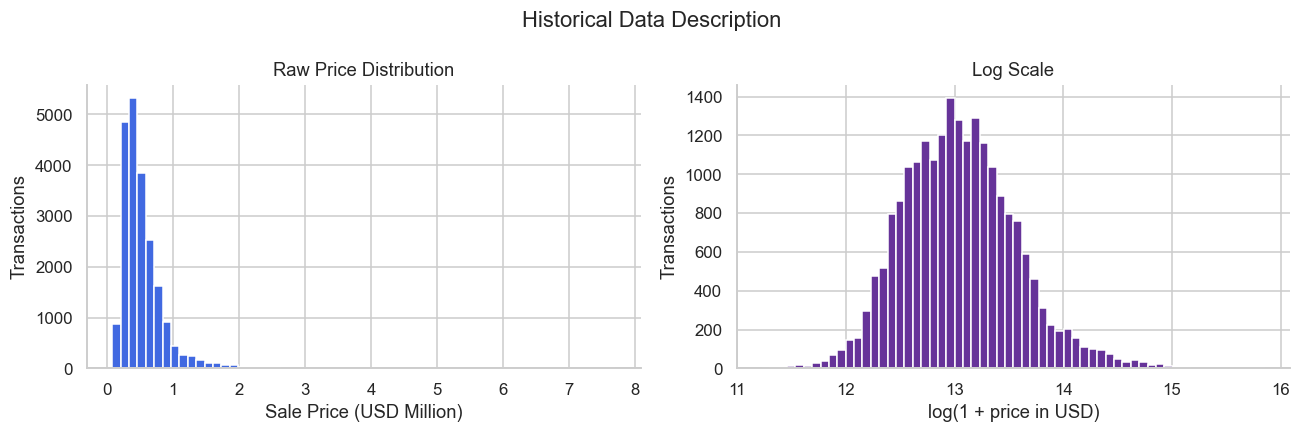

In [7]:
continuous = [
    'price', 
    'sqft_living', 
    'sqft_lot', 
    'sqft_above', 
    'sqft_basement',
    'sqft_living15', 
    'sqft_lot15'
]

iqr_rows = []
for col in continuous:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    extreme = ~df[col].between(lower, upper)
    iqr_rows.append({'feature': col,
                     'q1': q1,
                     'q3': q3,
                     'lower': lower,
                     'upper': upper,
                     'flagged_n': int(extreme.sum()),
                     'flagged_percentage': round(extreme.mean() * 100, 2)
                     })
iqr_report = pd.DataFrame(iqr_rows).set_index('feature')
display(iqr_report)

fig, axes = plt.subplots(1, 2, figsize = (12, 4))
axes[0].hist(df['price'] / 1e6, bins = 60, color = 'royalblue', edgecolor = 'white')
axes[0].set(xlabel = 'Sale Price (USD Million)', ylabel = 'Transactions', title = 'Raw Price Distribution')
axes[1].hist(np.log1p(df['price']), bins = 60, color = 'rebeccapurple', edgecolor = 'white')
axes[1].set(xlabel = 'log(1 + price in USD)', ylabel = 'Transactions', title = 'Log Scale')
fig.suptitle('Historical Data Description')
fig.tight_layout()
plt.show()

IQR flags identify observations that are extreme relative to the sample distribution; they do not prove data errors. High-price transactions are retained. A log transformation is an optional modeling experiment to evaluate on validation data, not a requirement that follows from a skewed histogram.

## 8. Bedroom Anomalies

,transactions
bedrooms,
0,13
1,199
2,2760
3,9824
4,6882
5,1601
6,272
7,38
8,13


,id,date,bedrooms,bathrooms,sqft_living,grade,price
8757,1773100755,2014-08-21,11,3.00,3000,7,520000.0
15870,2402100895,2014-06-25,33,1.75,1620,7,640000.0


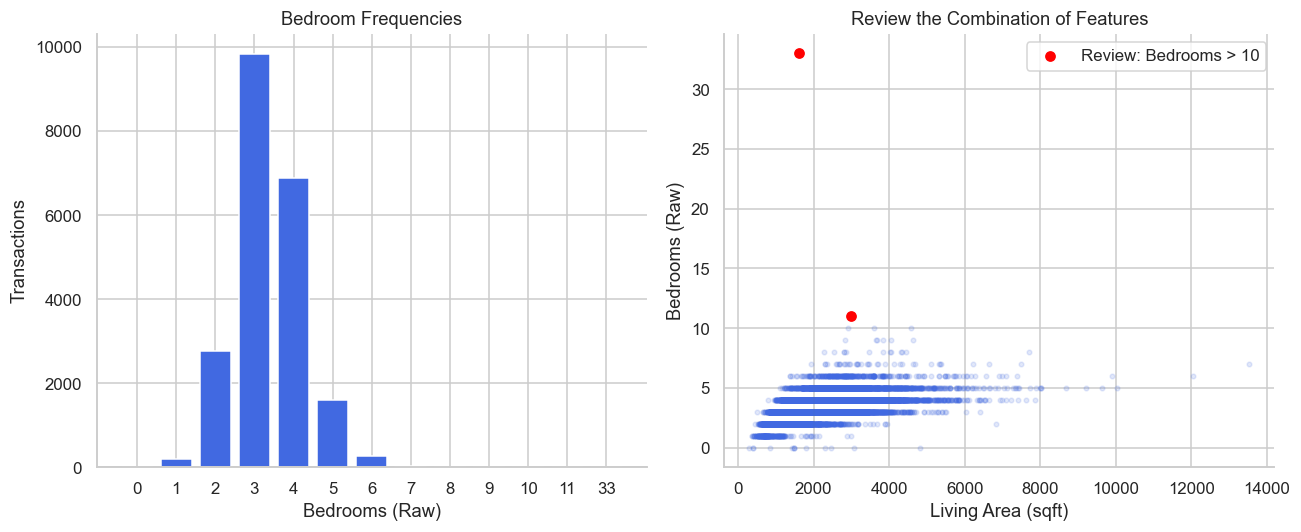

In [8]:
display(df['bedrooms'].value_counts().sort_index().rename('transactions').to_frame())
review_bedrooms = df['bedrooms'].gt(10)
display(df.loc[review_bedrooms, ['id', 'date', 'bedrooms', 'bathrooms', 'sqft_living', 'grade', 'price']])
fig, axes = plt.subplots(1, 2, figsize = (12, 5))
freq = df['bedrooms'].value_counts().sort_index()
axes[0].bar(freq.index.astype(str), freq.values, color = 'royalblue')
axes[0].set(xlabel = 'Bedrooms (Raw)', ylabel = 'Transactions', title = 'Bedroom Frequencies')
axes[1].scatter(df['sqft_living'], df['bedrooms'], s = 9, alpha = 0.15, color = 'royalblue')
axes[1].scatter(df.loc[review_bedrooms, 'sqft_living'], df.loc[review_bedrooms, 'bedrooms'], color = 'red', s = 65, edgecolor = 'white', label = 'Review: Bedrooms > 10')
axes[1].set(xlabel = 'Living Area (sqft)', ylabel = 'Bedrooms (Raw)', title = 'Review the Combination of Features')
axes[1].legend()
fig.tight_layout()
plt.show()

In [9]:
suspect = df.loc[df['bedrooms'].eq(33)]
display(suspect[['id', 'date', 'bedrooms', 'bathrooms', 'sqft_living', 'price']])
if not suspect.empty:
    area = suspect['sqft_living'].iloc[0]
    peers = df.loc[df['sqft_living'].eq(area), 'bedrooms']
    print(f'Transactions with {area} sqft of living area: {len(peers)}')
    print('Median bedrooms among transactions with the same living area:', peers.median())
    display(peers.value_counts().sort_index().rename('transactions').to_frame())

,id,date,bedrooms,bathrooms,sqft_living,price
15870,2402100895,2014-06-25,33,1.75,1620,640000.0


Transactions with 1620 sqft of living area: 99
Median bedrooms among transactions with the same living area: 3.0


,transactions
bedrooms,
2,14
3,64
4,20
33,1


One transaction records 33 bedrooms with 1,620 sqft of living area. The median bedroom count among transactions with the same living area is 3, but this does not verify the true bedroom count for that property. The raw value is preserved, a review flag is added, and the modeling value is set to missing pending verification. Any imputation will be fitted on training data only.

## 9. Rare Categories

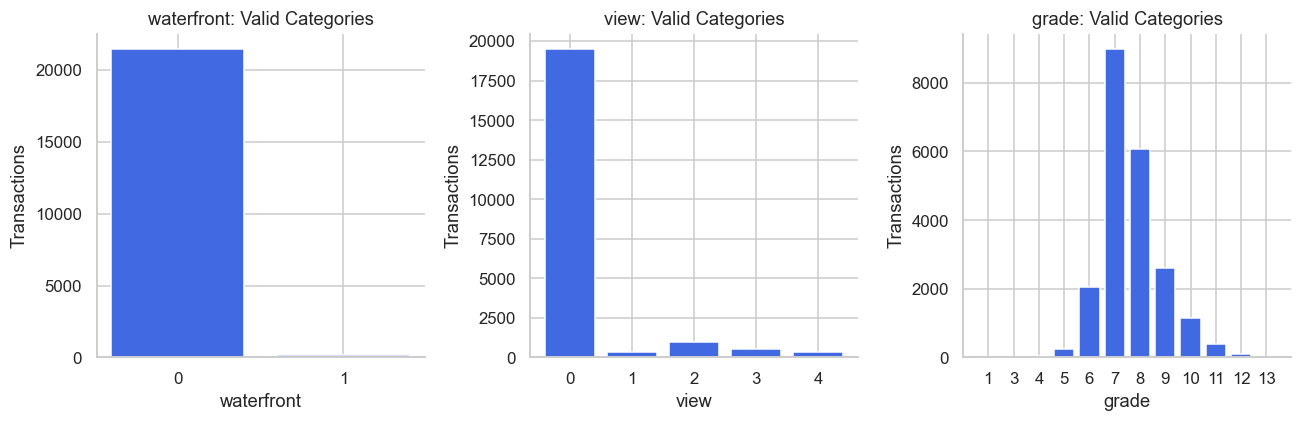

Waterfront Q1 / Q3: 0.0 / 0.0
Waterfront homes: 163


In [10]:
fig, axes = plt.subplots(1, 3, figsize = (12, 4))
for ax, feature in zip(axes, ['waterfront', 'view', 'grade']):
    counts = df[feature].value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values, color = 'royalblue')
    ax.set(title = f'{feature}: Valid Categories', xlabel = feature, ylabel = 'Transactions')
fig.tight_layout()
plt.show()

q1, q3 = df['waterfront'].quantile([0.25, 0.75])
print('Waterfront Q1 / Q3:', q1, '/', q3)
print('Waterfront homes:', int(df['waterfront'].eq(1).sum()))

All 163 waterfront observations are retained. Waterfront is a valid binary category; its rarity and zero IQR do not make the value 1 an error.

## 10. Time Coverage and Transaction Volume

,sales_count,first_observed,last_observed,median_price_usd
date,,,,
2014-05,1768,2014-05-02,2014-05-31,465000.0
2014-06,2180,2014-06-01,2014-06-30,465000.0
2014-07,2211,2014-07-01,2014-07-31,465000.0
2014-08,1940,2014-08-01,2014-08-31,442100.0
2014-09,1774,2014-09-01,2014-09-30,450000.0
2014-10,1878,2014-10-01,2014-10-31,446900.0
2014-11,1411,2014-11-01,2014-11-30,435000.0
2014-12,1471,2014-12-01,2014-12-31,432500.0
2015-01,978,2015-01-02,2015-01-31,438500.0


Transactions per Day at the End of the Observed Period:


,sales_count
date,
2015-05-06,88
2015-05-07,76
2015-05-08,54
2015-05-09,3
2015-05-10,2
2015-05-11,40
2015-05-12,49
2015-05-13,31
2015-05-14,11


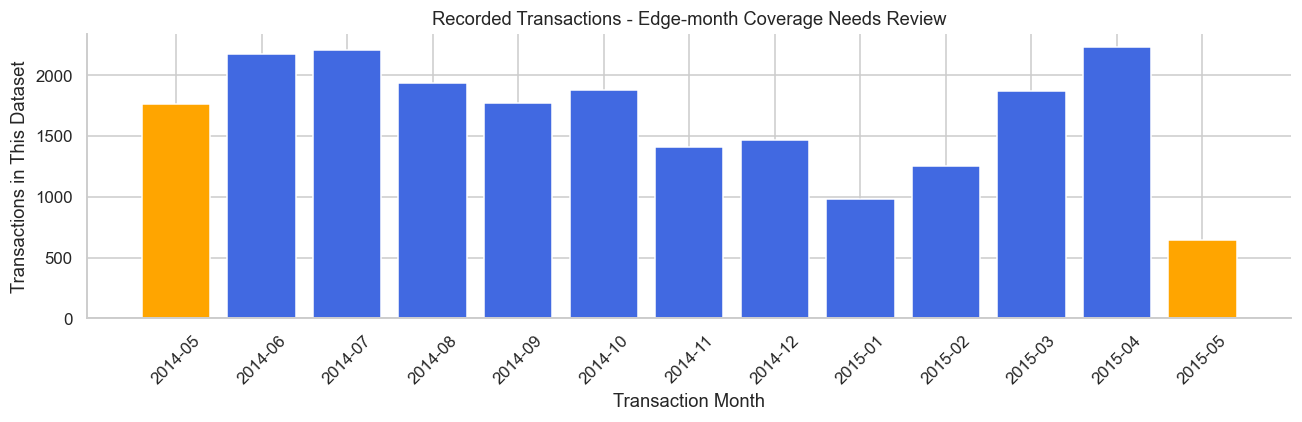

In [11]:
monthly = df.groupby(df['date'].dt.to_period('M')).agg(
    sales_count = ('id', 'size'),
    first_observed = ('date', 'min'),
    last_observed = ('date', 'max'),
    median_price_usd = ('price', 'median')
)
display(monthly)
print('Transactions per Day at the End of the Observed Period:')
display(df.groupby('date').size().tail(12).rename('sales_count').to_frame())

fig, ax = plt.subplots(figsize = (12, 4))
colors = ['orange' if i in (0, len(monthly) - 1) else 'royalblue' for i in range(len(monthly))]
ax.bar(monthly.index.astype(str), monthly['sales_count'], color = colors)
ax.set(title = 'Recorded Transactions - Edge-month Coverage Needs Review', 
       xlabel = 'Transaction Month',
       ylabel = 'Transactions in This Dataset')
ax.tick_params(axis = 'x', rotation = 45)
fig.tight_layout()
plt.show()

The monthly chart describes recorded transactions in this dataset, not latent demand. The first and last observed months require coverage review. Sparse records at the end of the dataset do not establish that market demand collapsed. The available period is insufficient to establish reliable annual seasonality.


## 11. Deterministic Cleaning and Decision Log

In [12]:
df_clean = df.copy(deep = True)
bedrooms_unverified = df['bedrooms'].eq(33)
built_after_sale = quality_flags['built_after_sale_year']
renovated_after_sale = quality_flags['renovated_after_sale_year']

df_clean['bedrooms_raw'] = df['bedrooms']
df_clean['bedrooms_unverified'] = bedrooms_unverified
df_clean['bedrooms'] = df['bedrooms'].astype(float).mask(bedrooms_unverified)

df_clean['yr_built_raw'] = df['yr_built']
df_clean['yr_built'] = df['yr_built'].astype(float).mask(built_after_sale)
df_clean['yr_renovated_raw'] = df['yr_renovated']
df_clean['yr_renovated'] = df['yr_renovated'].astype(float).mask(renovated_after_sale)

df_clean['house_age_at_sale_years'] = df_clean['date'].dt.year - df_clean['yr_built']
df_clean['was_renovated'] = df_clean['yr_renovated'].gt(0).astype(float)
df_clean.loc[df_clean['yr_renovated'].isna(), 'was_renovated'] = np.nan
df_clean['years_since_renovation'] = (df_clean['date'].dt.year - df_clean['yr_renovated']).where(df_clean['yr_renovated'].gt(0))

cleaning_decisions = pd.DataFrame([
    {
        'rule': 'bedrooms = 33, not externally verified', 'rows': int(bedrooms_unverified.sum()),
        'action': 'preserve raw, flag, set modeling value to NaN; train-only imputation later'
     },
    {
        'rule': 'yr_built after sale year', 'rows': int(built_after_sale.sum()),
        'action': 'preserve raw, quarantine modeling year; no clipping of negative age'
    },
    {
        'rule': 'yr_renovated after sale year', 'rows': int(renovated_after_sale.sum()),
        'action': 'preserve raw, quarantine modeling year and related renovation features'
    },
    {
        'rule': 'repeated property ID', 'rows': int(df.duplicated('id').sum()),
        'action': 'retain observations; keep IDs for split audit'
    },
    {
        'rule': 'high price by IQR', 'rows': int(iqr_report.loc['price', 'flagged_n']),
        'action': 'retain; inspect errors in expensive segment during model evaluation'
    }
])
display(cleaning_decisions)

,rule,rows,action
0,"bedrooms = 33, not externally verified",1,"preserve raw, flag, set modeling value to NaN;..."
1,yr_built after sale year,12,"preserve raw, quarantine modeling year; no cli..."
2,yr_renovated after sale year,6,"preserve raw, quarantine modeling year and rel..."
3,repeated property ID,177,retain observations; keep IDs for split audit
4,high price by IQR,1159,retain; inspect errors in expensive segment du...


Cleaning is deterministic and does not remove transactions or alter price. Original bedroom and year values are preserved. Year-based house age is an approximation, not an exact elapsed duration. Zero bedrooms and zero bathrooms remain flagged for review without an invented replacement value.


## 12. Verify Impact

In [13]:
pd.testing.assert_frame_equal(df_raw, raw_snapshot)
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == source_sha256
assert len(df_clean) == len(df_raw)
assert df_clean['id'].equals(df['id'])
assert df_clean['price'].equals(df['price'])
assert df_clean['date'].equals(df['date'])
assert df_clean.loc[~bedrooms_unverified, 'bedrooms'].eq(df.loc[~bedrooms_unverified, 'bedrooms']).all()
assert df_clean.loc[bedrooms_unverified, 'bedrooms'].isna().all()
assert df_clean.loc[bedrooms_unverified, 'bedrooms_raw'].eq(33).all()
assert df_clean['house_age_at_sale_years'].dropna().ge(0).all()

display(df_clean.loc[bedrooms_unverified, ['id', 'date', 'bedrooms_raw', 'bedrooms', 'bedrooms_unverified', 'sqft_living']])
display(df_clean[['bedrooms', 'yr_built', 'yr_renovated', 'house_age_at_sale_years', 'was_renovated', 'years_since_renovation']].isna().sum().rename('missing_after_policy').to_frame())

print('Passed: The raw file and df_raw are unchanged; all transactions are retained')
print('No imputation parameters were fitted on the full dataset.')


,id,date,bedrooms_raw,bedrooms,bedrooms_unverified,sqft_living
15870,2402100895,2014-06-25,33,NaN,True,1620


,missing_after_policy
bedrooms,1
yr_built,12
yr_renovated,6
house_age_at_sale_years,12
was_renovated,6
years_since_renovation,20705


Passed: The raw file and df_raw are unchanged; all transactions are retained
No imputation parameters were fitted on the full dataset.


In [14]:
assert df_clean.index.equals(df_raw.index), 'Reference export requires the original row order.'
assert len(df_clean) == len(df_raw)
assert df_clean['id'].equals(df_raw['id'])
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == source_sha256

reference_dir = ROOT / 'data' / 'reference'
assert reference_dir.is_dir(), f'Folder has not been found: {reference_dir.resolve()}'
reference_path = reference_dir / 'audit_clean_reference.csv'
reference = df_clean.copy()
reference.insert(0, 'source_row', np.arange(1, len(reference) + 1))
reference.to_csv(reference_path, index = False, date_format = '%Y-%m-%d')

quality_summary.to_csv(reference_dir / 'audit_quality_reference.csv', index_label = 'check_name')
duplicate_report.to_frame().to_csv(reference_dir / 'audit_duplicates_reference.csv', index_label = 'check_name')
manifest = {
    'source_sha256': source_sha256,
    'reference_sha256': hashlib.sha256(reference_path.read_bytes()).hexdigest(),
    'row_count': len(reference),
    'raw_columns': df_raw.columns.tolist(),
    'clean_columns': df_clean.columns.tolist(),
}
(reference_dir / 'audit_reference_manifest.json').write_text(
    json.dumps(manifest, indent=2), encoding='utf-8'
)
print('Exported the audit reference, quality checks, duplicate checks, and manifest.')
print('Reference shape:', reference.shape)


Exported the audit reference, quality checks, duplicate checks, and manifest.
Reference shape: (21613, 29)


The raw file and df_raw remain unchanged, and all 21,613 transactions are retained. The cleaned data contain 1 missing bedroom value, 12 missing construction years, and 6 missing renovation years. The 20,705 missing years_since_renovation values comprise 20,699 records with no recorded renovation and 6 quarantined future renovation years; they are not 20,705 newly discovered data errors. No imputation parameters were fitted on the full dataset.